# Introduction

This notebook demonstrates how to accelerate topic modeling at scale using <b>BERTopic</b> with <b>NVIDIA GPU acceleration</b>. We explore how drop-in GPU support for <b>UMAP</b> and <b>HDBSCAN</b> via <b>cuML</b> can significantly reduce runtime without changing existing code.

Our example uses the [<b>Amazon Electronics Reviews dataset</b>](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Electronics.jsonl.gz) , which contains over <b>43.9M product reviews </b>.

We then walk through a BERTopic pipeline using GPU-accelerated components to extract interpretable topics and visualize them. The dramatic speedup from CPU to GPU execution highlights the impact of GPU-powered NLP workflows. Note that this timing reflects a single run on a specific system configuration and may vary across different hardware setups.


# BERTopic Introduction

A diagram showing BERTopic's workflow:
<p style="text-align: center;">
  <img src="BERTopic diagram.png" width="750">
</p>


In [1]:
# VERY FIRST CELL - Run this BEFORE importing anything
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'  # Use only one GB300
# Verify it's set
print(f"CUDA_VISIBLE_DEVICES = {os.environ['CUDA_VISIBLE_DEVICES']}")

CUDA_VISIBLE_DEVICES = 0


In [2]:
import plotly.io as pio
pio.renderers.default = "notebook"

# Load and Preprocess Text

In [3]:
%load_ext cudf.pandas
import pandas as pd

Uncomment the code to load the dataset

In [ ]:
!wget https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Electronics.jsonl.gz --no-check-certificate

In [ ]:
path = "Electronics.jsonl.gz"
data = pd.read_json(
    path,
    lines=True,
    nrows=1_000_000,        # only first 700k rows are read
    compression="gzip",   # optional; usually inferred from .gz
)
amazon_review = data["text"].tolist()

In [7]:
import re

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text
    
# preprocess each text string 
preprocessed_texts = [preprocess_text(str(review)) for review in amazon_review]

In [8]:
print(len(amazon_review))
print(len(preprocessed_texts))

1000000
1000000


# GPU BERTopic

## Load the cuML Libraries

In [9]:
%load_ext cuml.accel

from hdbscan import HDBSCAN
from umap import UMAP
from bertopic import BERTopic

## Compute Embeddings Once

In [10]:
%%time
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")  # or your chosen model
embeddings = model.encode(preprocessed_texts, show_progress_bar=True)

Batches:   0%|          | 0/31250 [00:00<?, ?it/s]

CPU times: user 2h 43min 15s, sys: 4min 7s, total: 2h 47min 22s
Wall time: 8min


In [ ]:
# pd.DataFrame(embeddings).to_csv("embeddings_4M.csv")

## Create UMAP and HDBSCAN Instances

In [11]:
# Create instances of GPU-accelerated UMAP and HDBSCAN
umap_model = UMAP(n_components=5, n_neighbors=15, min_dist=0.0)
hdbscan_model = HDBSCAN(min_cluster_size=50, min_samples=10, gen_min_span_tree=True, prediction_data=True)

## Build a BERTopic Model

In [ ]:
# Pass the above models to be used in BERTopic
topic_model = BERTopic(umap_model=umap_model, hdbscan_model=hdbscan_model)
topics, probs = topic_model.fit_transform(preprocessed_texts, embeddings=embeddings)

topic_model.visualize_topics()

[2025-12-17 14:07:44.285] [CUML] [info] Building knn graph using nn descent (configured from build_algo='auto')


## Get Topic ID and Topic Keywords

In [13]:
# Get the topic keywords
topic_info = topic_model.get_topic_info()  # Returns a DataFrame with topic details
topic_info  # Includes Topic ID and top keywords

,Topic,Count,Name,Representation,Representative_Docs
0,-1,474017,-1_sound_headphones_these_they,"[sound, headphones, these, they, them, ear, my...",[let me say this at the beginning i never thou...
1,0,9499,0_alexa_echo_dot_dots,"[alexa, echo, dot, dots, show, voice, ask, mus...","[for alexa i love it, alexa alexa alexa what c..."
2,1,8006,1_keyboard_keys_keyboards_key,"[keyboard, keys, keyboards, key, typing, ipad,...",[ill start off by saying that ive been using n...
3,2,6314,2_cables_cable_length_flexible,"[cables, cable, length, flexible, braided, con...","[great cables for a good price, these are good..."
4,3,5710,3_mouse_mice_scroll_wheel,"[mouse, mice, scroll, wheel, logitech, hand, c...","[i can use my mouse again, small mouse but wor..."
...,...,...,...,...,...
1579,1578,50,1578_work_these_theses_great,"[work, these, theses, great, things, thanks, a...","[these work great, these work great, these wor..."
1580,1579,50,1579_camera_great_lil_dslr,"[camera, great, lil, dslr, wow, yes, described...","[great camera, great camera, great camera]"
1581,1580,50,1580_uses_loves_wife_everyday,"[uses, loves, wife, everyday, husband, he, dai...",[my husband loves this he uses it all the time...
1582,1581,50,1581_aaaaaaaaa_aaaaaa_aaaaaaa_aaa,"[aaaaaaaaa, aaaaaa, aaaaaaa, aaa, excellent, a...","[excellent aaaaaaaaa, excellent aaaaaaaaa, exc..."


## Visualize Distribution of Topics

array([[<Axes: title={'center': '0'}>]], dtype=object)

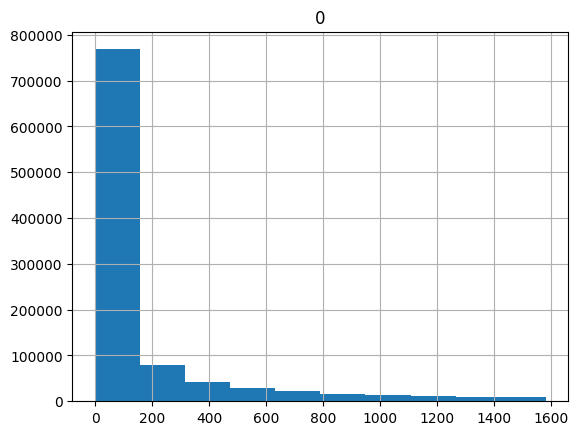

In [37]:
pd.DataFrame(topics).hist()

## Visualize Barchart

In [38]:
topic_model.visualize_barchart(top_n_topics=8)

## Visualize Heatmap

In [39]:
topic_model.visualize_heatmap(top_n_topics=100)

## Visualize Document DataMap

[2025-12-17 14:07:05.966] [CUML] [info] Building knn graph using nn descent (configured from build_algo='auto')
CPU times: user 8.58 s, sys: 4.99 s, total: 13.6 s
Wall time: 6.94 s


<InteractiveFigure width=1200 height=750>
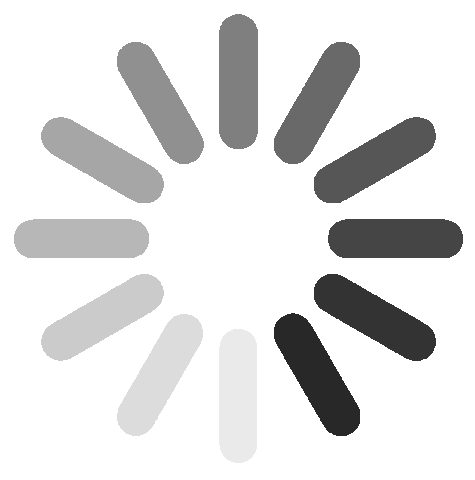

In [40]:
%%time
import copy

n = int(len(topics)*0.01)
temp_model = copy.copy(topic_model)
temp_model.topics_ = topic_model.topics_[:n]

temp_model.visualize_document_datamap(
    preprocessed_texts[:n],
    embeddings=embeddings[:n], 
    interactive=True
)